In [1]:
import os
import numpy as np
import pynwb
import pandas as pd
from matplotlib import pyplot as plt
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

In [2]:
path = '../data/2025-worm-fieseler/allworms/exported_data_gfp_freely_moving/'
filenames = os.listdir(path)
filename = filenames[0]
nwbfile = pynwb.read_nwb(path + filename)

/home/julian-zim/.venv/hgm/lib/python3.12/site-packages/hdmf/spec/namespace.py:535: UserWarning: Ignoring cached namespace 'core' version 2.7.0 because version 2.8.0 is already loaded.
  warn("Ignoring cached namespace '%s' version %s because version %s is already loaded."


In [3]:
def plotgrid(datas, timestampss, labels):
	ncols = 4
	nplots = len(datas)

	nrows = (nplots + ncols - 1) // ncols
	fig, axes = plt.subplots(nrows=nrows, ncols=ncols, figsize=(15, nrows * 4))
	axes = axes.flatten()

	for i in range(nplots):
		ax = axes[i]

		x = timestampss[i] if timestampss is not None else None
		y = datas[i]
		l = labels[i]

		ax.plot(x, y) if x is not None else ax.plot(y)
		ax.set_title(f"Plot {i+1}")
		ax.set_xlabel("Time (s)")
		ax.set_ylabel(l)

		if i >= nplots:
			ax.set_visible(False)

	plt.tight_layout()
	plt.show()

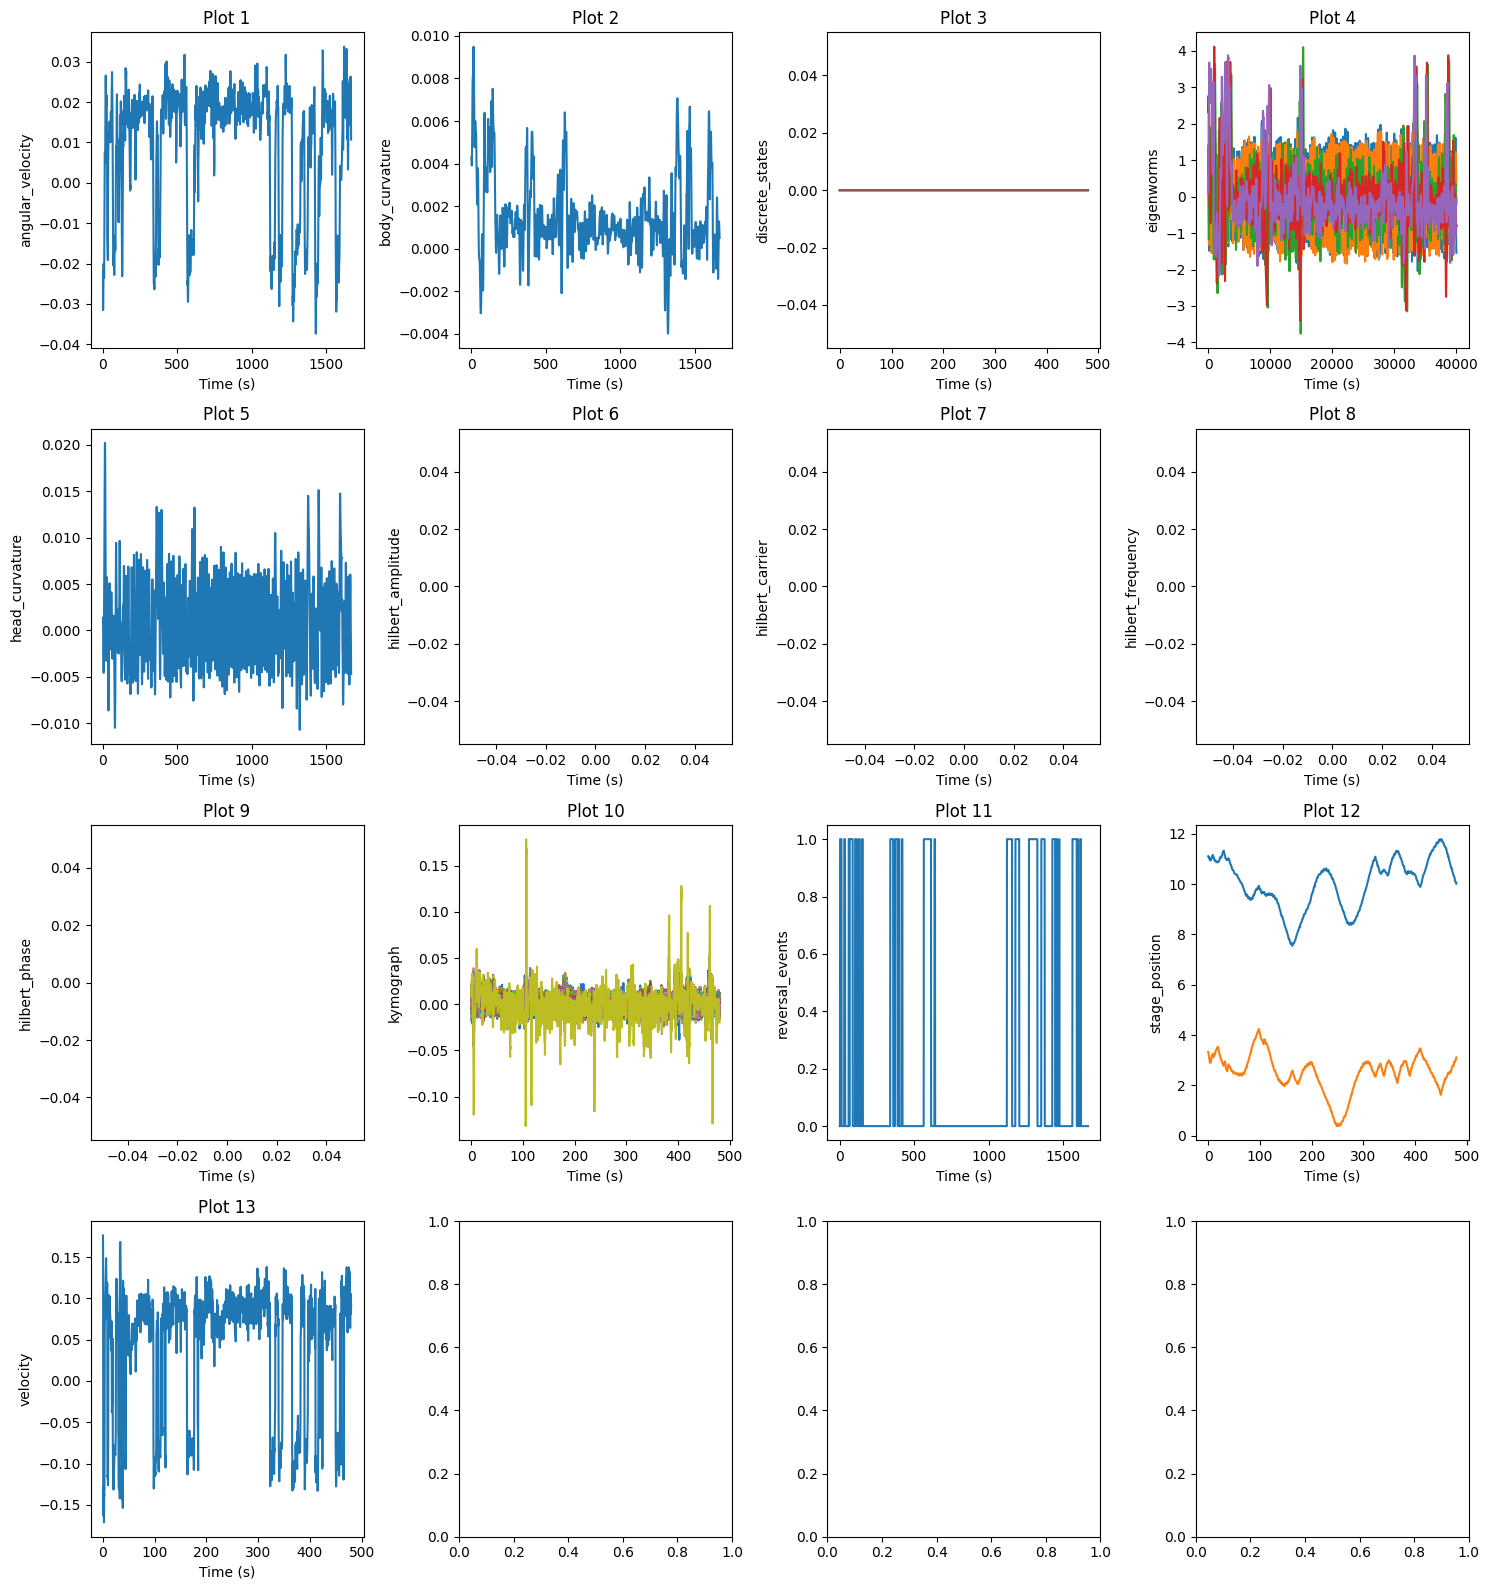

In [4]:
behavioral_data = nwbfile.processing['Behavior'].data_interfaces

labels_behav = list()
timestampss_behav = list()
datas_behav = list()
for key in behavioral_data.keys():
	#print(key)
	data = behavioral_data[key].time_series[key].data[:]
	timestamps = behavioral_data[key].time_series[key].timestamps[:]

	labels_behav.append(key)
	timestampss_behav.append(timestamps)
	datas_behav.append(data)

plotgrid(datas_behav, timestampss_behav, labels_behav)

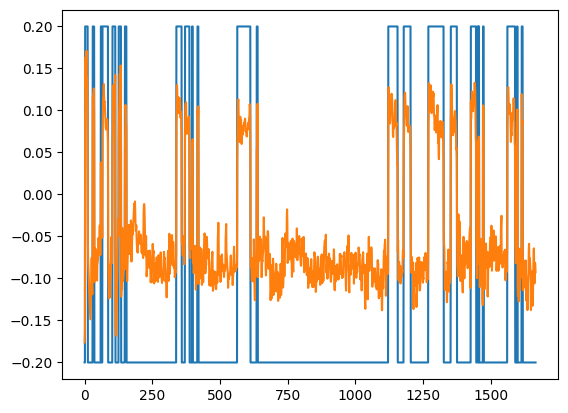

In [5]:
x1, x2 = timestampss_behav[10], timestampss_behav[12]
y1, y2 = datas_behav[10] * 0.4 - 0.2, datas_behav[12] * (-1)

plt.plot(x1, y1, y2)

SignalFluorescence
SignalDFoF


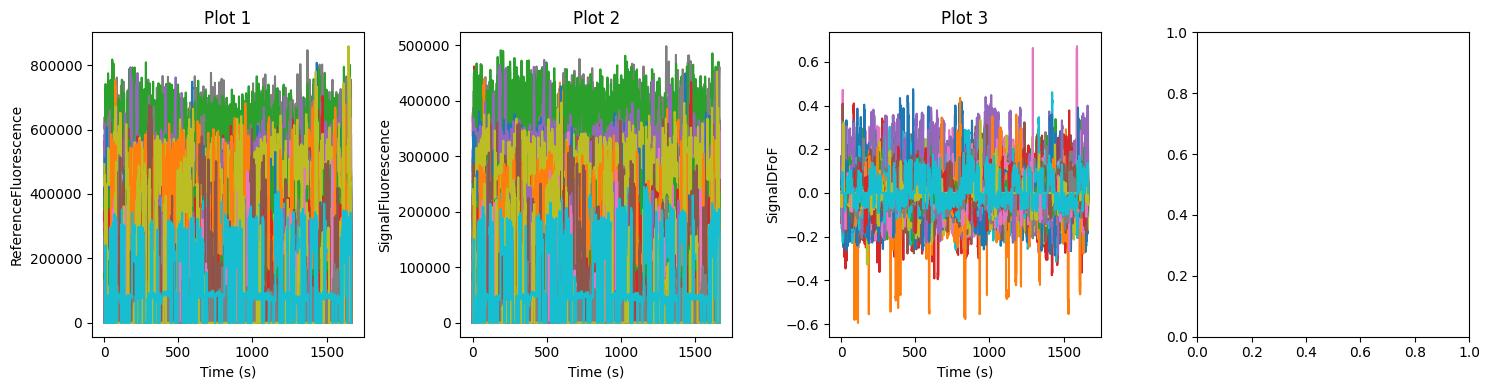

In [6]:
calcium_data = nwbfile.processing['CalciumActivity'].data_interfaces

datas_calci = list()
labels_calci = list()
datas_calci.append(calcium_data['ReferenceFluorescence'].roi_response_series['ReferenceCalciumImResponseSeries'].data[:])
labels_calci.append('ReferenceFluorescence')
for key in ['SignalFluorescence', 'SignalDFoF']:
	print(key)
	data = calcium_data[key].roi_response_series['SignalCalciumImResponseSeries'].data[:]
	datas_calci.append(data)
	labels_calci.append(key)

plotgrid(datas_calci, None, labels_calci)

In [7]:
dfof_calci = datas_calci[0].T  # dfoverf

xtick_positions = np.arange(0, dfof_calci.shape[1], 200)
xtick_labels = [f'{x / 3.472222222222222:.1f}' for x in xtick_positions]

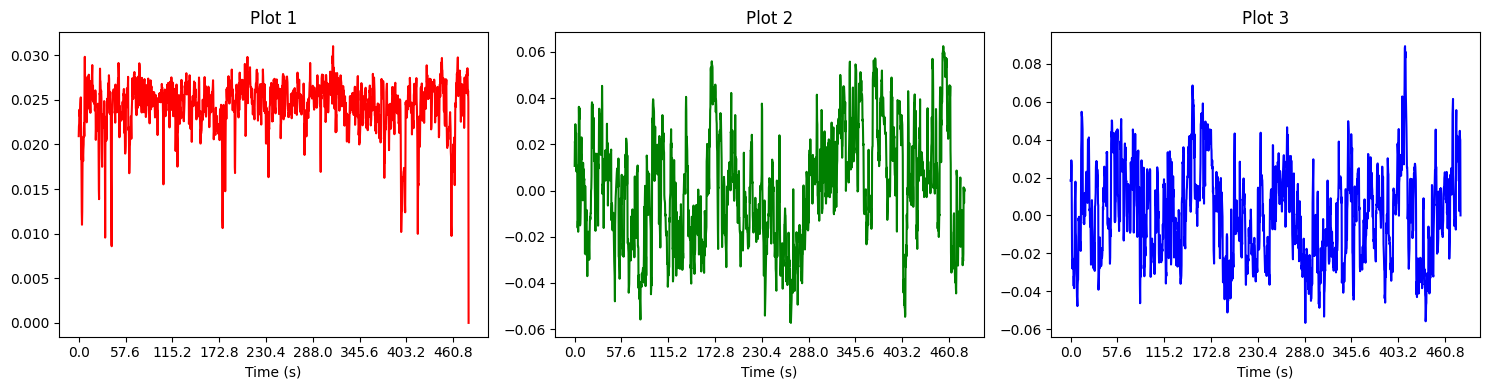

In [8]:
pca = PCA(n_components=3)
pca_res = pca.fit_transform(dfof_calci)

fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(15, 4))
axes = axes.flatten()
for i in range(3):
	ax = axes[i]
	ax.plot(pca.components_[i], color=['red', 'green', 'blue'][i])
	ax.set_title(f"Plot {i+1}")
	ax.set_xlabel("Time (s)")
	ax.set_xticks(xtick_positions, xtick_labels)
plt.tight_layout()
plt.show()

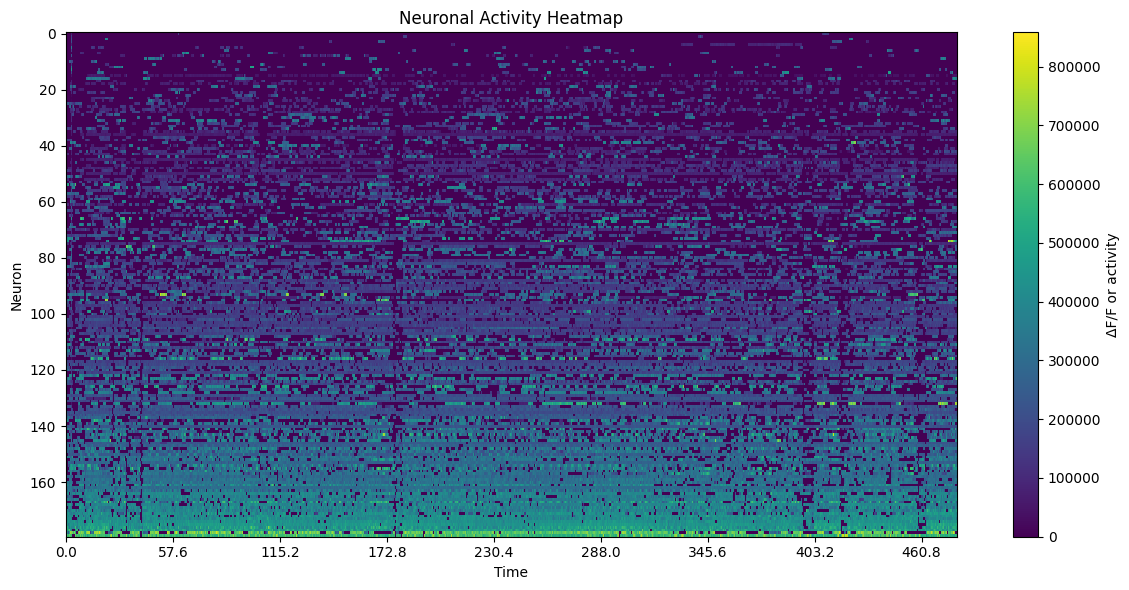

In [9]:
indices = np.argsort(pca_res[:, 0])
dfof_calci_sorted = dfof_calci[indices]

plt.figure(figsize=(12, 6))
plt.imshow(dfof_calci_sorted, aspect='auto', cmap='viridis', interpolation='none')

plt.colorbar(label='ΔF/F or activity')
plt.xlabel('Time')
plt.ylabel('Neuron')
plt.title('Neuronal Activity Heatmap')
plt.xticks(xtick_positions, xtick_labels)
plt.tight_layout()
plt.show()
